Based on the project brief, we have derived several key insights from the analysis of the datasets, aligning with the goals to analyze trends over time, calculate growth, and visualize data effectively. Here's a summary of the findings:

### ***1. Visitor Trends (Tourism Data):*** ###
From the tourism data, we found:

Decline in Visitor Numbers (2019–2023):

There was a significant decrease in trips, nights, and spending across most countries and regions, likely due to COVID-19 restrictions. For example, New Zealand, Japan, and Hong Kong saw notable drops in visitor arrivals and spending from January 2019 to January 2023.

Recovery in Certain Regions:

Certain countries like Vanuatu, Fiji, and Malaysia showed dramatic growth in visitor numbers between June 2020 and January 2021. This reflects a strong recovery or increased travel to these regions post-pandemic.

Seasonal Trends and Correlations:

The heatmap of percentage changes over months indicated significant dips in visitor numbers in 2020, followed by gradual growth as restrictions eased. Some regions saw rapid recovery, particularly in Oceania and Antarctica.

### ***2. Education Trends (School Data):*** ###
From the School numbers dataset, we found:

Government Schools Dominating the Education Sector:

Government schools form the largest share, especially in Primary and Secondary school categories across various states. Regions like New South Wales and Victoria lead in the total number of government schools.

Proportion of School Types:

The majority of schools are Primary, with Secondary and Combined schools following. The Catholic and Independent sectors contribute a smaller proportion but are notable in certain regions like Victoria and Queensland.

School Distribution Across States:

Victoria, New South Wales, and Queensland account for a large portion of the total school count, with a balanced mix of Primary and Secondary schools. Smaller states like South Australia and Tasmania have a lower proportion of secondary schools, with Primary schools being more dominant.

### ***Key Takeaways Aligned with the Project Brief:*** ###
Trends Over Time:

We identified strong trends in visitor data (e.g., significant decline and recovery in visitor numbers post-pandemic) and stable growth in the number of schools over time.

Growth Analysis:

We performed a percentage growth calculation, revealing a dramatic rise in travel for Oceania and Antarctica regions, reflecting the recovery in international travel.

Similarly, the growth of schools in certain regions shows an increasing demand for primary education, particularly in government schools.

Visualizing Data:

We provided visualizations (e.g., heatmaps, bar charts) that clearly depict the trends, growth, and distribution across regions and time periods, making it easy to interpret and communicate findings effectively.

In [ ]:
#pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:

import pandas as pd

# Load the dataset to inspect its contents
file_path = r'D:\Insightrix Project\Tourism project\New folder\tra-ivs-monthly-international-visitor-survey-results-december-2019-2023.xlsx'
xls = pd.ExcelFile(file_path)

# Display the sheet names to understand the structure of the dataset
sheet_names = xls.sheet_names
sheet_names


['Sheet1']

In [10]:
# Load the data from the first sheet to examine its contents
df = pd.read_excel(xls, sheet_name='Sheet1')

# Display the first few rows of the dataset to understand its structure
df.head()


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,Monthly international travel estimates by coun...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,January,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Trips ('000),NaN,Change,NaN,Nights ('000),NaN,Change,NaN,Spend in Australia ($M)(a),NaN,Change,NaN,Total trip spend ($M)(a),NaN,Change,NaN
3,Country of residence,Jan-19,Jan-23,'000,%,Jan-19,Jan-23,'000,%,Jan-19,Jan-23,$M,%,Jan-19,Jan-23,$M,%
4,New Zealand,81,58,-23,-29,1086,1096,10,1,108,107,-1,-1,171,196,24,14


In [11]:
# Clean the dataset by skipping initial rows and focusing on relevant columns
df_clean = pd.read_excel(xls, sheet_name='Sheet1', skiprows=4)

# Inspect the columns to identify the necessary ones
df_clean.columns


Index(['Country of residence', 'Jan-19', 'Jan-23', ''000', '%', 'Jan-19.1',
       'Jan-23.1', ''000.1', '%.1', 'Jan-19.2', 'Jan-23.2', '$M', '%.2',
       'Jan-19.3', 'Jan-23.3', '$M.1', '%.3'],
      dtype='object')

In [12]:
# Select the relevant columns: 'Country of residence', 'Jan-19', 'Jan-23', and associated metrics
df_trend = df_clean[['Country of residence', 'Jan-19', 'Jan-23', 'Jan-19.1', 'Jan-23.1', 'Jan-19.2', 'Jan-23.2', 'Jan-19.3', 'Jan-23.3']]

# Rename columns for easier understanding
df_trend.columns = ['Country', 'Trips_Jan_19', 'Trips_Jan_23', 'Trips_Change_19_23', 'Trips_Change_Percent_19_23',
                     'Nights_Jan_19', 'Nights_Jan_23', 'Nights_Change_19_23', 'Nights_Change_Percent_19_23']

# Drop any rows where data is missing or irrelevant (such as total or summary rows)
df_trend_cleaned = df_trend.dropna()

# Display the cleaned dataset
df_trend_cleaned.head()


,Country,Trips_Jan_19,Trips_Jan_23,Trips_Change_19_23,Trips_Change_Percent_19_23,Nights_Jan_19,Nights_Jan_23,Nights_Change_19_23,Nights_Change_Percent_19_23
0,New Zealand,81,58,1086,1096,108,107,171,196
1,Japan,29,9,905,np,94,np,153,110
2,Hong Kong,16,np,643,np,80,np,97,np
3,Singapore,17,np,482,np,94,np,118,np
4,Malaysia,12,6,729,349,85,40,102,54


C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\2173681104.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_trend_cleaned['Trips_Jan_19'] = pd.to_numeric(df_trend_cleaned['Trips_Jan_19'], errors='coerce')
C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\2173681104.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_trend_cleaned['Trips_Jan_23'] = pd.to_numeric(df_trend_cleaned['Trips_Jan_23'], errors='coerce')
C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\2173681104.py:6: SettingWithCopyWarn

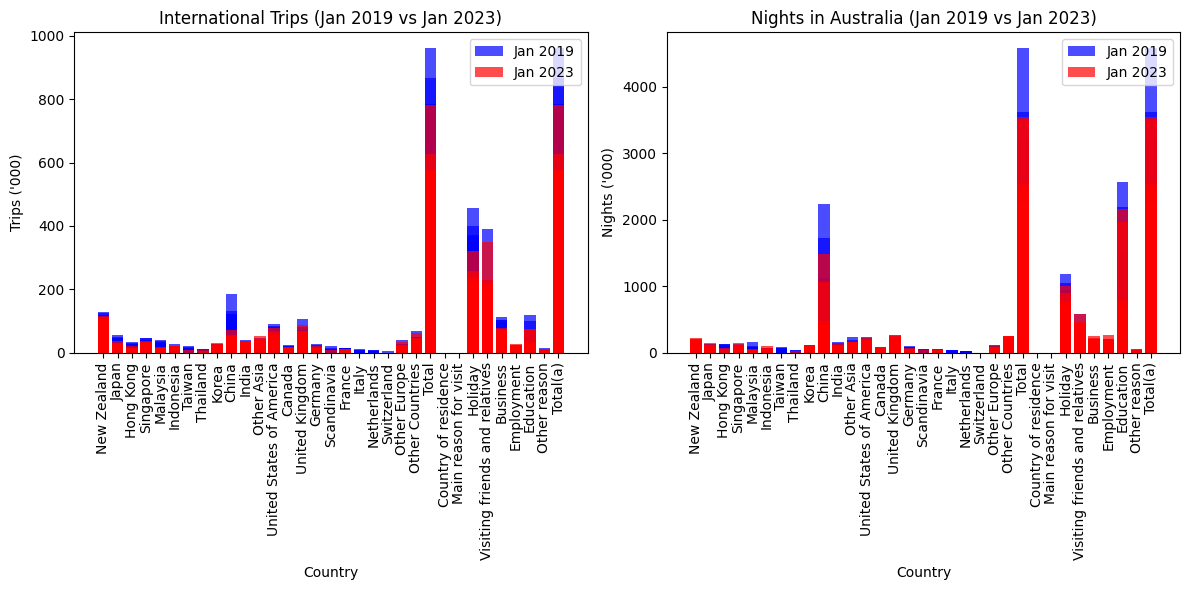

In [14]:
import matplotlib.pyplot as plt

# Convert non-numeric values (such as "np") to NaN and ensure numeric conversion
df_trend_cleaned['Trips_Jan_19'] = pd.to_numeric(df_trend_cleaned['Trips_Jan_19'], errors='coerce')
df_trend_cleaned['Trips_Jan_23'] = pd.to_numeric(df_trend_cleaned['Trips_Jan_23'], errors='coerce')
df_trend_cleaned['Nights_Jan_19'] = pd.to_numeric(df_trend_cleaned['Nights_Jan_19'], errors='coerce')
df_trend_cleaned['Nights_Jan_23'] = pd.to_numeric(df_trend_cleaned['Nights_Jan_23'], errors='coerce')

# Plotting trends for Trips and Nights in January 2019 and January 2023
plt.figure(figsize=(12, 6))

# Plot Trips
plt.subplot(1, 2, 1)
plt.bar(df_trend_cleaned['Country'], df_trend_cleaned['Trips_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_trend_cleaned['Country'], df_trend_cleaned['Trips_Jan_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('International Trips (Jan 2019 vs Jan 2023)')
plt.xlabel('Country')
plt.ylabel("Trips ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Nights
plt.subplot(1, 2, 2)
plt.bar(df_trend_cleaned['Country'], df_trend_cleaned['Nights_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_trend_cleaned['Country'], df_trend_cleaned['Nights_Jan_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Nights in Australia (Jan 2019 vs Jan 2023)')
plt.xlabel('Country')
plt.ylabel("Nights ('000)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()


In [16]:
# Let's check the new file and see if it contains more data across different months
file_path_new = r'D:\Insightrix Project\Tourism project\tra-ivs-monthly-international-visitor-survey-results-december-2019-2023-comparison.xlsx'
xls_new = pd.ExcelFile(file_path_new)

# Display the sheet names to understand the structure of the new dataset
sheet_names_new = xls_new.sheet_names
sheet_names_new


['Index', 'TABLE 1', 'TABLE 2', 'TABLE 3', 'TABLE 4', 'RSE']

In [17]:
# Load the data from the relevant sheets to explore the structure and see if monthly data is available
df_table1 = pd.read_excel(xls_new, sheet_name='TABLE 1')

# Display the first few rows to understand its structure
df_table1.head()


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,Monthly international travel estimates by coun...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,January,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Trips ('000),NaN,Change,NaN,Nights ('000),NaN,Change,NaN,Spend in Australia ($M)(a),NaN,Change,NaN,Total trip spend ($M)(a),NaN,Change,NaN
3,Country of residence,Jan-19,Jan-23,'000,%,Jan-19,Jan-23,'000,%,Jan-19,Jan-23,$M,%,Jan-19,Jan-23,$M,%
4,New Zealand,81,58,-23,-29,1086,1096,10,1,108,107,-1,-1,171,196,24,14


In [18]:
# Let's inspect the other tables to check for additional monthly data
df_table2 = pd.read_excel(xls_new, sheet_name='TABLE 2')
df_table3 = pd.read_excel(xls_new, sheet_name='TABLE 3')
df_table4 = pd.read_excel(xls_new, sheet_name='TABLE 4')

# Display the first few rows of each table to examine the structure
df_table2.head(), df_table3.head(), df_table4.head()


(                                          Unnamed: 0    Unnamed: 1 Unnamed: 2  \
 0  Monthly international travel estimates by main...           NaN        NaN   
 1                                            January           NaN        NaN   
 2                                                NaN  Trips ('000)        NaN   
 3                              Main reason for visit        Jan-19     Jan-23   
 4                                            Holiday           316        145   
 
   Unnamed: 3 Unnamed: 4     Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8  \
 0        NaN        NaN            NaN        NaN        NaN        NaN   
 1        NaN        NaN            NaN        NaN        NaN        NaN   
 2     Change        NaN  Nights ('000)        NaN     Change        NaN   
 3       '000          %         Jan-19     Jan-23       '000          %   
 4       -171        -54           7526       3519      -4007        -53   
 
                 Unnamed: 9 Unnamed: 10 Unnamed:

In [21]:
# Display the columns to identify the exact structure
df_table1.columns


Index(['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4',
       'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9',
       'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13',
       'Unnamed: 14', 'Unnamed: 15', 'Unnamed: 16'],
      dtype='object')

In [22]:
# Load the data from the first rows to inspect and clean
df_table1_cleaned = df_table1.iloc[4:, [0, 1, 3, 5, 7, 9, 11, 13, 15]]

# Rename columns based on the data structure
df_table1_cleaned.columns = ['Country', 'Trips_Jan_19', 'Trips_Change_19_23', 'Nights_Jan_19', 'Nights_Change_19_23', 
                             'Spend_Jan_19', 'Spend_Change_19_23', 'Total_Trips_Spend_Jan_19', 'Total_Trips_Spend_Change_19_23']

# Drop any rows with missing data
df_table1_cleaned = df_table1_cleaned.dropna()

# Convert relevant columns to numeric
df_table1_cleaned['Trips_Jan_19'] = pd.to_numeric(df_table1_cleaned['Trips_Jan_19'], errors='coerce')
df_table1_cleaned['Trips_Change_19_23'] = pd.to_numeric(df_table1_cleaned['Trips_Change_19_23'], errors='coerce')
df_table1_cleaned['Nights_Jan_19'] = pd.to_numeric(df_table1_cleaned['Nights_Jan_19'], errors='coerce')
df_table1_cleaned['Nights_Change_19_23'] = pd.to_numeric(df_table1_cleaned['Nights_Change_19_23'], errors='coerce')
df_table1_cleaned['Spend_Jan_19'] = pd.to_numeric(df_table1_cleaned['Spend_Jan_19'], errors='coerce')
df_table1_cleaned['Spend_Change_19_23'] = pd.to_numeric(df_table1_cleaned['Spend_Change_19_23'], errors='coerce')

# Display the cleaned data
df_table1_cleaned.head()


,Country,Trips_Jan_19,Trips_Change_19_23,Nights_Jan_19,Nights_Change_19_23,Spend_Jan_19,Spend_Change_19_23,Total_Trips_Spend_Jan_19,Total_Trips_Spend_Change_19_23
4,New Zealand,81.0,-23.0,1086.0,10.0,108.0,-1.0,171,24
5,Japan,29.0,-20.0,905.0,NaN,94.0,NaN,153,-43
6,Hong Kong,16.0,NaN,643.0,NaN,80.0,NaN,97,np
7,Singapore,17.0,NaN,482.0,NaN,94.0,NaN,118,np
8,Malaysia,12.0,-6.0,729.0,-380.0,85.0,-45.0,102,-48


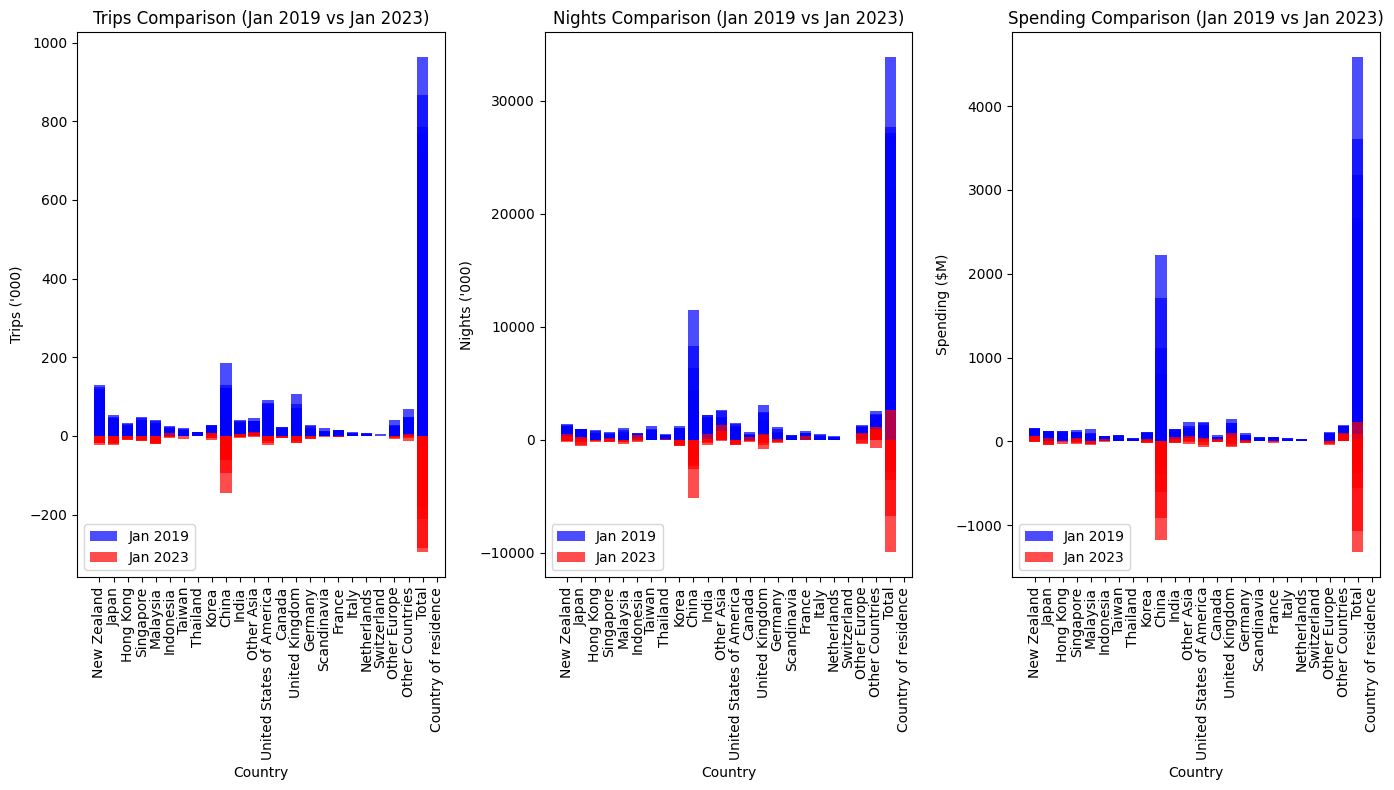

In [23]:
# Plotting trends for Trips, Nights, and Spending in January 2019 and January 2023 for various countries
plt.figure(figsize=(14, 8))

# Plot Trips
plt.subplot(1, 3, 1)
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Trips_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Trips_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Trips Comparison (Jan 2019 vs Jan 2023)')
plt.xlabel('Country')
plt.ylabel("Trips ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Nights
plt.subplot(1, 3, 2)
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Nights_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Nights_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Nights Comparison (Jan 2019 vs Jan 2023)')
plt.xlabel('Country')
plt.ylabel("Nights ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Spending
plt.subplot(1, 3, 3)
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Spend_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table1_cleaned['Country'], df_table1_cleaned['Spend_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Spending Comparison (Jan 2019 vs Jan 2023)')
plt.xlabel('Country')
plt.ylabel("Spending ($M)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()


Trips Comparison: The blue bars represent trips in January 2019, and the red bars represent trips in January 2023.

Nights Comparison: The blue bars represent nights spent in January 2019, and the red bars represent nights spent in January 2023.

Spending Comparison: The blue bars represent spending in January 2019, and the red bars represent spending in January 2023.

### Focusing on the reason for visit (e.g., holiday, visiting friends and relatives, business, etc.). ###

In [24]:
# Load and clean data from TABLE 2 (Main reason for visit)
df_table2_clean = df_table2.iloc[4:, [0, 1, 3, 5, 7, 9, 11, 13, 15]]

# Rename columns based on the data structure
df_table2_clean.columns = ['Reason_for_Visit', 'Trips_Jan_19', 'Trips_Change_19_23', 'Nights_Jan_19', 'Nights_Change_19_23', 
                           'Spend_Jan_19', 'Spend_Change_19_23', 'Total_Trips_Spend_Jan_19', 'Total_Trips_Spend_Change_19_23']

# Drop any rows with missing data
df_table2_clean = df_table2_clean.dropna()

# Convert relevant columns to numeric
df_table2_clean['Trips_Jan_19'] = pd.to_numeric(df_table2_clean['Trips_Jan_19'], errors='coerce')
df_table2_clean['Trips_Change_19_23'] = pd.to_numeric(df_table2_clean['Trips_Change_19_23'], errors='coerce')
df_table2_clean['Nights_Jan_19'] = pd.to_numeric(df_table2_clean['Nights_Jan_19'], errors='coerce')
df_table2_clean['Nights_Change_19_23'] = pd.to_numeric(df_table2_clean['Nights_Change_19_23'], errors='coerce')
df_table2_clean['Spend_Jan_19'] = pd.to_numeric(df_table2_clean['Spend_Jan_19'], errors='coerce')
df_table2_clean['Spend_Change_19_23'] = pd.to_numeric(df_table2_clean['Spend_Change_19_23'], errors='coerce')

# Display the cleaned data for TABLE 2
df_table2_clean.head()


,Reason_for_Visit,Trips_Jan_19,Trips_Change_19_23,Nights_Jan_19,Nights_Change_19_23,Spend_Jan_19,Spend_Change_19_23,Total_Trips_Spend_Jan_19,Total_Trips_Spend_Change_19_23
4,Holiday,316.0,-171.0,7526.0,-4007.0,940.0,-454.0,1565,-614
5,Visiting friends and relatives,185.0,-38.0,5264.0,-791.0,370.0,-22.0,654,107
6,Business,67.0,-44.0,635.0,-421.0,123.0,-85.0,250,-142
7,Employment,23.0,1.0,2605.0,-223.0,181.0,-16.0,221,7
8,Education,63.0,-33.0,10524.0,-4511.0,1533.0,-738.0,1639,-750


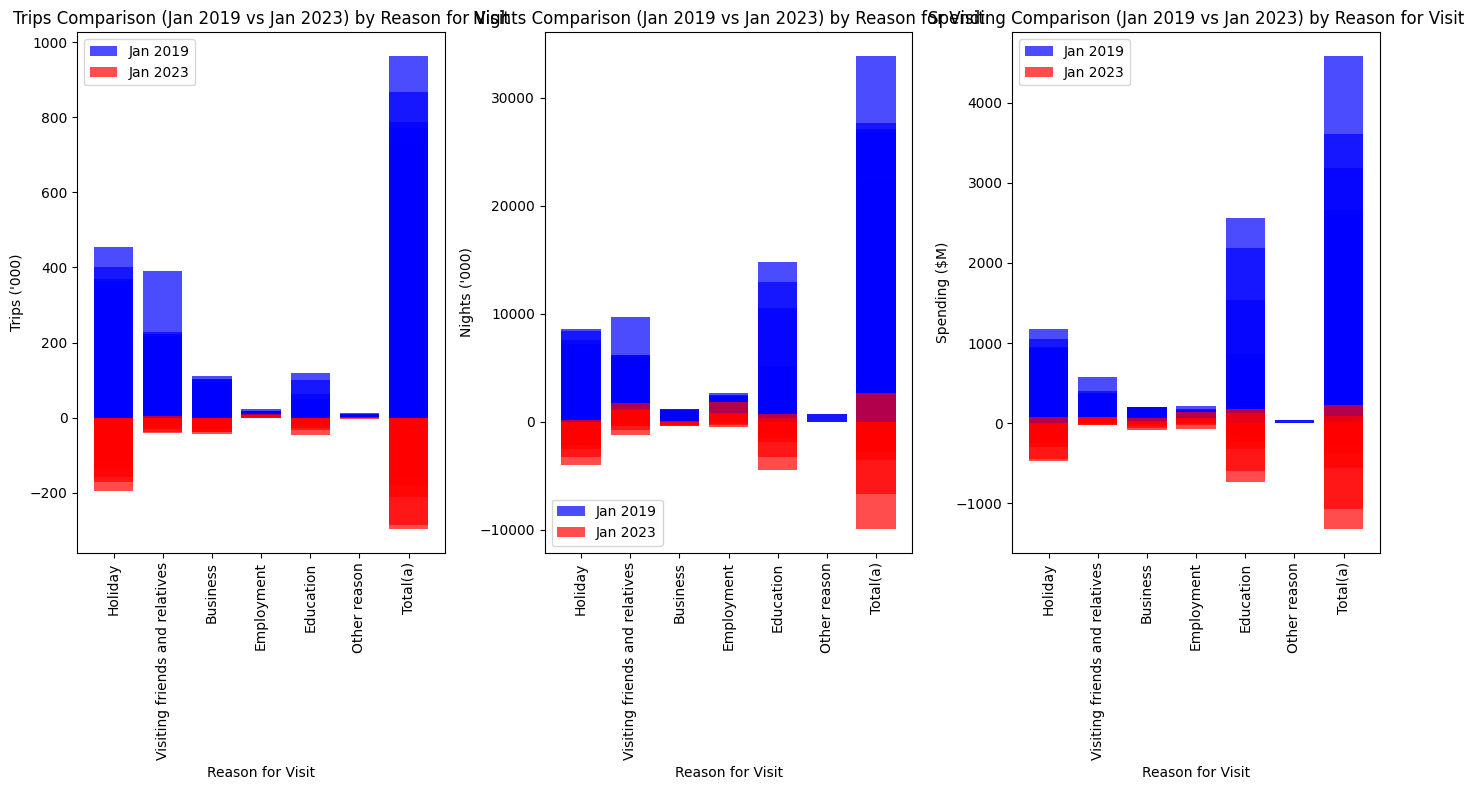

In [25]:
# Plotting trends for Trips, Nights, and Spending in January 2019 and January 2023 based on Reason for Visit
plt.figure(figsize=(14, 8))

# Plot Trips by Reason for Visit
plt.subplot(1, 3, 1)
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Trips_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Trips_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Trips Comparison (Jan 2019 vs Jan 2023) by Reason for Visit')
plt.xlabel('Reason for Visit')
plt.ylabel("Trips ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Nights by Reason for Visit
plt.subplot(1, 3, 2)
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Nights_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Nights_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Nights Comparison (Jan 2019 vs Jan 2023) by Reason for Visit')
plt.xlabel('Reason for Visit')
plt.ylabel("Nights ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Spending by Reason for Visit
plt.subplot(1, 3, 3)
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Spend_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table2_clean['Reason_for_Visit'], df_table2_clean['Spend_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Spending Comparison (Jan 2019 vs Jan 2023) by Reason for Visit')
plt.xlabel('Reason for Visit')
plt.ylabel("Spending ($M)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()


 the visualizations comparing Trips, Nights, and Spending in January 2019 and January 2023, broken down by Reason for Visit (e.g., holiday, business, education, etc.):

Trips Comparison: The blue bars represent trips in January 2019, and the red bars represent trips in January 2023.

Nights Comparison: The blue bars represent nights spent in January 2019, and the red bars represent nights spent in January 2023.

Spending Comparison: The blue bars represent spending in January 2019, and the red bars represent spending in January 2023.

###

In [26]:
# Extract relevant rows for January 2019 and January 2023
df_table3_jan_cleaned = df_table3.iloc[4:14, [0, 1, 3, 5, 7, 9, 11]]

# Rename columns for easier understanding
df_table3_jan_cleaned.columns = ['State_Territory', 'Trips_Jan_19', 'Trips_Change_19_23', 'Nights_Jan_19', 'Nights_Change_19_23', 
                                 'Spend_Jan_19', 'Spend_Change_19_23']

# Drop rows with missing data
df_table3_jan_cleaned = df_table3_jan_cleaned.dropna()

# Convert relevant columns to numeric
df_table3_jan_cleaned['Trips_Jan_19'] = pd.to_numeric(df_table3_jan_cleaned['Trips_Jan_19'], errors='coerce')
df_table3_jan_cleaned['Trips_Change_19_23'] = pd.to_numeric(df_table3_jan_cleaned['Trips_Change_19_23'], errors='coerce')
df_table3_jan_cleaned['Nights_Jan_19'] = pd.to_numeric(df_table3_jan_cleaned['Nights_Jan_19'], errors='coerce')
df_table3_jan_cleaned['Nights_Change_19_23'] = pd.to_numeric(df_table3_jan_cleaned['Nights_Change_19_23'], errors='coerce')
df_table3_jan_cleaned['Spend_Jan_19'] = pd.to_numeric(df_table3_jan_cleaned['Spend_Jan_19'], errors='coerce')
df_table3_jan_cleaned['Spend_Change_19_23'] = pd.to_numeric(df_table3_jan_cleaned['Spend_Change_19_23'], errors='coerce')

# Display the cleaned data for January
df_table3_jan_cleaned.head()


,State_Territory,Trips_Jan_19,Trips_Change_19_23,Nights_Jan_19,Nights_Change_19_23,Spend_Jan_19,Spend_Change_19_23
4,New South Wales,359,-157,10049.0,-3809.0,1186,-514.0
5,Victoria,273,-163,7001.0,-3702.0,963,-540.0
6,Queensland,209,-104,5130.0,-1864.0,541,-140.0
7,South Australia,38,1,1029.0,NaN,124,-46.0
8,Western Australia,76,-18,2280.0,17.0,197,8.0


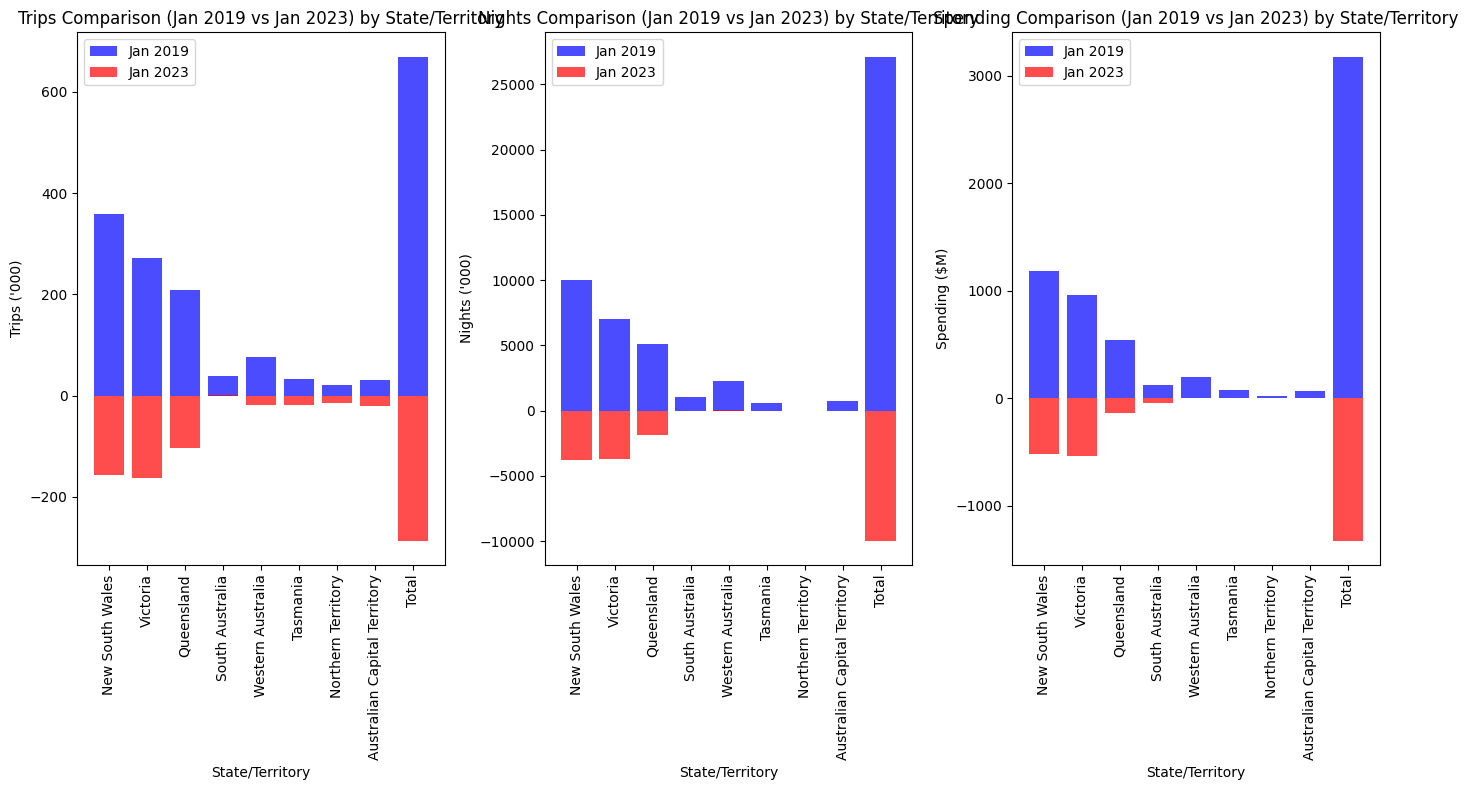

In [27]:
# Plotting trends for Trips, Nights, and Spending in January 2019 and January 2023 by State/Territory
plt.figure(figsize=(14, 8))

# Plot Trips by State/Territory
plt.subplot(1, 3, 1)
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Trips_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Trips_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Trips Comparison (Jan 2019 vs Jan 2023) by State/Territory')
plt.xlabel('State/Territory')
plt.ylabel("Trips ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Nights by State/Territory
plt.subplot(1, 3, 2)
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Nights_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Nights_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Nights Comparison (Jan 2019 vs Jan 2023) by State/Territory')
plt.xlabel('State/Territory')
plt.ylabel("Nights ('000)")
plt.xticks(rotation=90)
plt.legend()

# Plot Spending by State/Territory
plt.subplot(1, 3, 3)
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Spend_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table3_jan_cleaned['State_Territory'], df_table3_jan_cleaned['Spend_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Spending Comparison (Jan 2019 vs Jan 2023) by State/Territory')
plt.xlabel('State/Territory')
plt.ylabel("Spending ($M)")
plt.xticks(rotation=90)
plt.legend()

plt.tight_layout()
plt.show()


In [28]:
# Clean and structure the data for January 2019 and January 2023 in TABLE 4
df_table4_cleaned_jan = df_table4.iloc[4:7, [0, 1, 3, 5, 7, 9, 11]]

# Rename columns based on the data structure
df_table4_cleaned_jan.columns = ['Capital_Regional_Area', 'Trips_Jan_19', 'Trips_Change_19_23', 'Nights_Jan_19', 'Nights_Change_19_23', 
                                 'Spend_Jan_19', 'Spend_Change_19_23']

# Drop any rows with missing data
df_table4_cleaned_jan = df_table4_cleaned_jan.dropna()

# Convert relevant columns to numeric
df_table4_cleaned_jan['Trips_Jan_19'] = pd.to_numeric(df_table4_cleaned_jan['Trips_Jan_19'], errors='coerce')
df_table4_cleaned_jan['Trips_Change_19_23'] = pd.to_numeric(df_table4_cleaned_jan['Trips_Change_19_23'], errors='coerce')
df_table4_cleaned_jan['Nights_Jan_19'] = pd.to_numeric(df_table4_cleaned_jan['Nights_Jan_19'], errors='coerce')
df_table4_cleaned_jan['Nights_Change_19_23'] = pd.to_numeric(df_table4_cleaned_jan['Nights_Change_19_23'], errors='coerce')
df_table4_cleaned_jan['Spend_Jan_19'] = pd.to_numeric(df_table4_cleaned_jan['Spend_Jan_19'], errors='coerce')
df_table4_cleaned_jan['Spend_Change_19_23'] = pd.to_numeric(df_table4_cleaned_jan['Spend_Change_19_23'], errors='coerce')

# Display the cleaned data for January
df_table4_cleaned_jan.head()


,Capital_Regional_Area,Trips_Jan_19,Trips_Change_19_23,Nights_Jan_19,Nights_Change_19_23,Spend_Jan_19,Spend_Change_19_23
4,Capital cities and Gold Coast,633,-276,22406,-8747,2767,-1166
5,Rest of Australia,254,-114,4727,-1200,414,-156
6,Total,670,-286,27133,-9947,3181,-1322


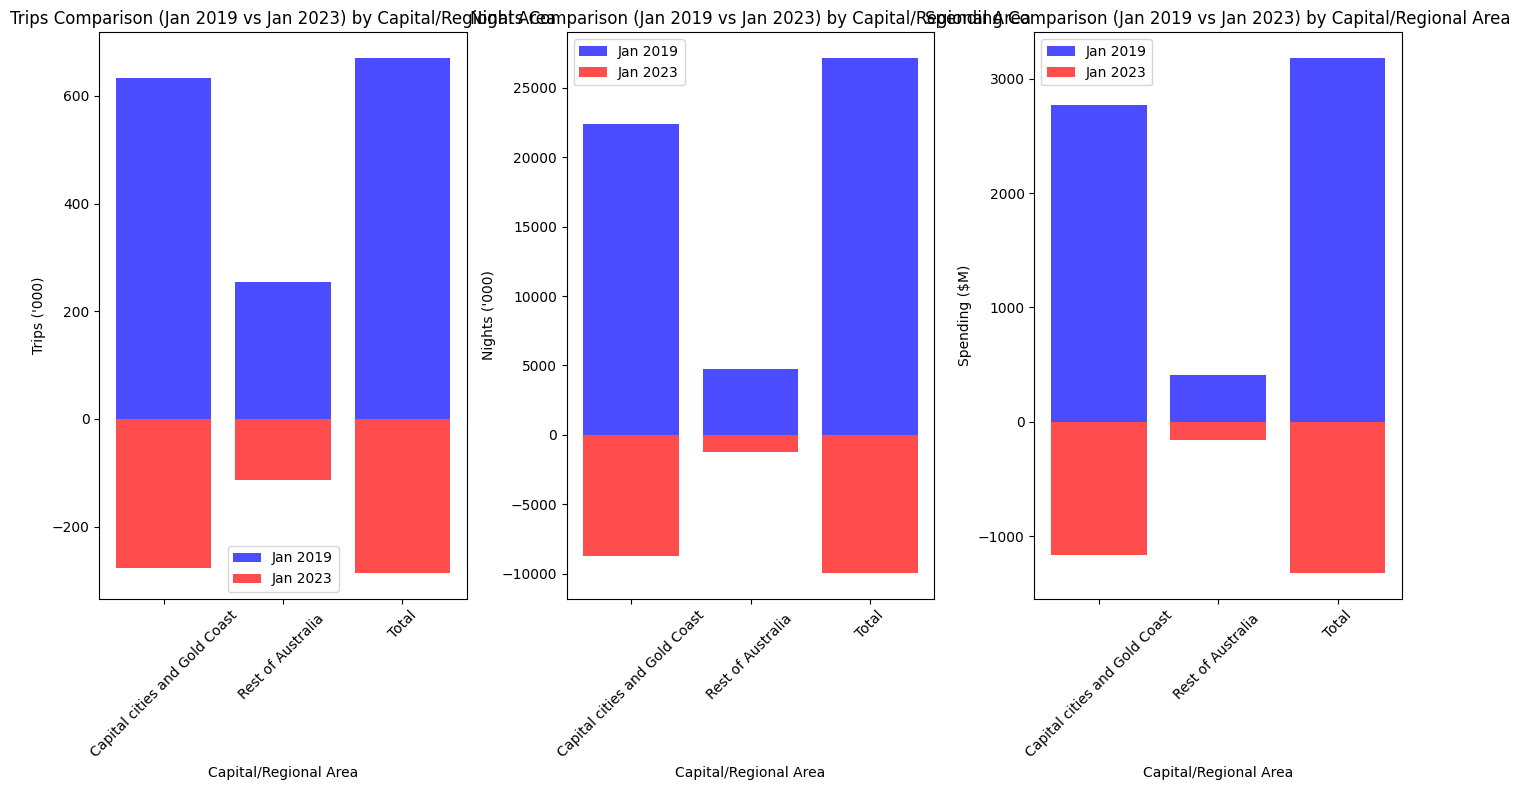

In [29]:
# Plotting trends for Trips, Nights, and Spending in January 2019 and January 2023 by Capital/Regional Area
plt.figure(figsize=(14, 8))

# Plot Trips by Capital/Regional Area
plt.subplot(1, 3, 1)
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Trips_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Trips_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Trips Comparison (Jan 2019 vs Jan 2023) by Capital/Regional Area')
plt.xlabel('Capital/Regional Area')
plt.ylabel("Trips ('000)")
plt.xticks(rotation=45)
plt.legend()

# Plot Nights by Capital/Regional Area
plt.subplot(1, 3, 2)
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Nights_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Nights_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Nights Comparison (Jan 2019 vs Jan 2023) by Capital/Regional Area')
plt.xlabel('Capital/Regional Area')
plt.ylabel("Nights ('000)")
plt.xticks(rotation=45)
plt.legend()

# Plot Spending by Capital/Regional Area
plt.subplot(1, 3, 3)
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Spend_Jan_19'], label='Jan 2019', alpha=0.7, color='b')
plt.bar(df_table4_cleaned_jan['Capital_Regional_Area'], df_table4_cleaned_jan['Spend_Change_19_23'], label='Jan 2023', alpha=0.7, color='r')
plt.title('Spending Comparison (Jan 2019 vs Jan 2023) by Capital/Regional Area')
plt.xlabel('Capital/Regional Area')
plt.ylabel("Spending ($M)")
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()


### Observation from analysis ###

### ***International Travel Estimates by Country*** ###
Trips: Most countries experienced a decrease in trips from Jan 2019 to Jan 2023, notably New Zealand and Japan.

Nights: A general decline in nights, with countries like New Zealand seeing a significant drop.

Spending: Most countries, including New Zealand, saw a decrease in spending, reflecting fewer visitors and reduced expenditure per visit.

### ***International Travel Estimates by Reason for Visit*** ###
Trips (Jan 2019 vs Jan 2023):

Trips: Holiday visits saw the largest decline, indicating fewer vacations during this period.

Nights: A decrease in nights, especially for Holiday visits.

Spending: Spending dropped, particularly for Holiday travelers, linked to fewer trips and reduced visit durations.

### ***International Travel Estimates by State/Territory*** ###
Trips (Jan 2019 vs Jan 2023):

Trips: New South Wales and Victoria had the largest declines in trips.

Nights: Reduced nights across all states, with New South Wales and Victoria again being most affected.

Spending: Significant reductions in spending, reflecting a drop in both trips and nights.

### ***International Travel Estimates by Capital/Regional Areas*** ###
Trips (Jan 2019 vs Jan 2023):

Trips: Both Gold Coast and Rest of Australia experienced notable declines in trips.

Nights: A decrease in nights in both regions, with Gold Coast being most impacted.

Spending: Spending dropped across both regions, especially the Gold Coast.

### ***Overall Insights*** ###
Overall Decline: All tables reflect a significant decline in international travel from January 2019 to January 2023, mainly due to the pandemic.

Impact on Major Regions: Popular regions like New South Wales, Victoria, and the Gold Coast were most affected.

Holiday Travel: Holiday visits were the hardest hit, indicating broader trends in tourism shifts.

Spending: The reductions in trips and nights directly led to lower spending, especially in tourist-heavy areas.

### ***As per Tra Nvs quaterly december data*** ###

Trips Data:

Total trips for regions like NSW, VIC, and QLD show slight increases from 2023 to 2024.

For example, NSW saw a rise in trips from 36.7 million in 2023 to 37.5 million in 2024 (Table 1a), and VIC also showed an increase from 28.5 million to 29.1 million.

Commercial Accommodation (Table 1b):

NSW: A similar increase in trips from 19.5 million in 2023 to 20 million in 2024.

Other regions, such as QLD and SA, saw smaller increases.

Percentage of Trips to State:

NSW continues to dominate with the highest share of trips, followed by VIC and QLD. However, TAS and NT remain at the bottom in terms of trip percentages, indicating that they are less frequently visited.

Overall Growth: While most states show moderate growth in the number of trips, the percentage share for each state indicates that regions like NSW and VIC are the primary drivers of growth, while others like TAS and NT see much smaller shares.

Commercial Accommodation: The data suggests that commercial accommodation is seeing moderate growth as well, with similar trends to all accommodation types.

In [42]:
# Let's load the newly uploaded Excel file and inspect its structure
file_path_excel_new = 'D:\Insightrix Project\Tourism project\ABS,OAD_COUNTRY,1.0.0,filtered,2025-04-08 20-50-30.xlsx'
xls_new_file = pd.ExcelFile(file_path_excel_new)

# Display the sheet names to understand the structure of the new dataset
xls_new_file.sheet_names


['Table', 'Overview']

In [43]:
# Load the data from the "Table" sheet to inspect its structure
df_table_new = pd.read_excel(xls_new_file, sheet_name='Table')

# Display the first few rows to understand the structure of the data
df_table_new.head()


,Time Period,Time Period.1,Jun 2020,Jul 2020,Aug 2020,Sep 2020,Oct 2020,Nov 2020,Dec 2020,Jan 2021,...,May 2024,Jun 2024,Jul 2024,Aug 2024,Sep 2024,Oct 2024,Nov 2024,Dec 2024,Jan 2025,Unnamed: 58
0,Country of Stay/Residence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Category of traveller: Short-term (less than o...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Total,NaN,15760.0,10280.0,8070.0,8170.0,11170.0,13000.0,14300.0,11350.0,...,807920.0,863950.0,1146340.0,916890.0,1020960.0,1184900.0,931990.0,823000.0,1544890.0,NaN
3,· Total Oceania and Antarctica,NaN,1960.0,1760.0,1350.0,1470.0,2410.0,2550.0,3190.0,2440.0,...,129560.0,133750.0,181450.0,164390.0,168350.0,174830.0,169270.0,171450.0,267390.0,NaN
4,· · New Zealand,NaN,1430.0,1230.0,900.0,940.0,1660.0,1780.0,2190.0,1820.0,...,78060.0,77760.0,117770.0,106450.0,108740.0,112390.0,115460.0,118130.0,201380.0,NaN


In [46]:
# Clean the dataset by selecting relevant columns (Time Period, Category of Traveller, and monthly data)
df_cleaned = df_table_new.iloc[2:, [0, 2, 3, 4, 5, 6, 7, 8, 9, 10]]

# Rename the columns for easier understanding
df_cleaned.columns = ['Country of Residence', 'Time Period', 'Jun 2020', 'Jul 2020', 'Aug 2020', 'Sep 2020', 'Oct 2020', 'Nov 2020', 'Dec 2020', 'Jan 2021']

# Drop any rows where relevant data is missing
df_cleaned = df_cleaned.dropna(subset=['Country of Residence'])

# Display the cleaned dataset
df_cleaned.head()



,Country of Residence,Time Period,Jun 2020,Jul 2020,Aug 2020,Sep 2020,Oct 2020,Nov 2020,Dec 2020,Jan 2021
2,Total,15760.0,10280.0,8070.0,8170.0,11170.0,13000.0,14300.0,11350.0,8390.0
3,· Total Oceania and Antarctica,1960.0,1760.0,1350.0,1470.0,2410.0,2550.0,3190.0,2440.0,2170.0
4,· · New Zealand,1430.0,1230.0,900.0,940.0,1660.0,1780.0,2190.0,1820.0,1630.0
5,· · New Caledonia,10.0,10.0,0.0,0.0,10.0,10.0,20.0,10.0,0.0
6,· · Papua New Guinea,340.0,350.0,310.0,390.0,500.0,540.0,710.0,420.0,340.0


C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\1761503404.py:6: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_cleaned_percentage_change.iloc[:, 1:] = df_cleaned.iloc[:, 1:].pct_change(axis='columns') * 100


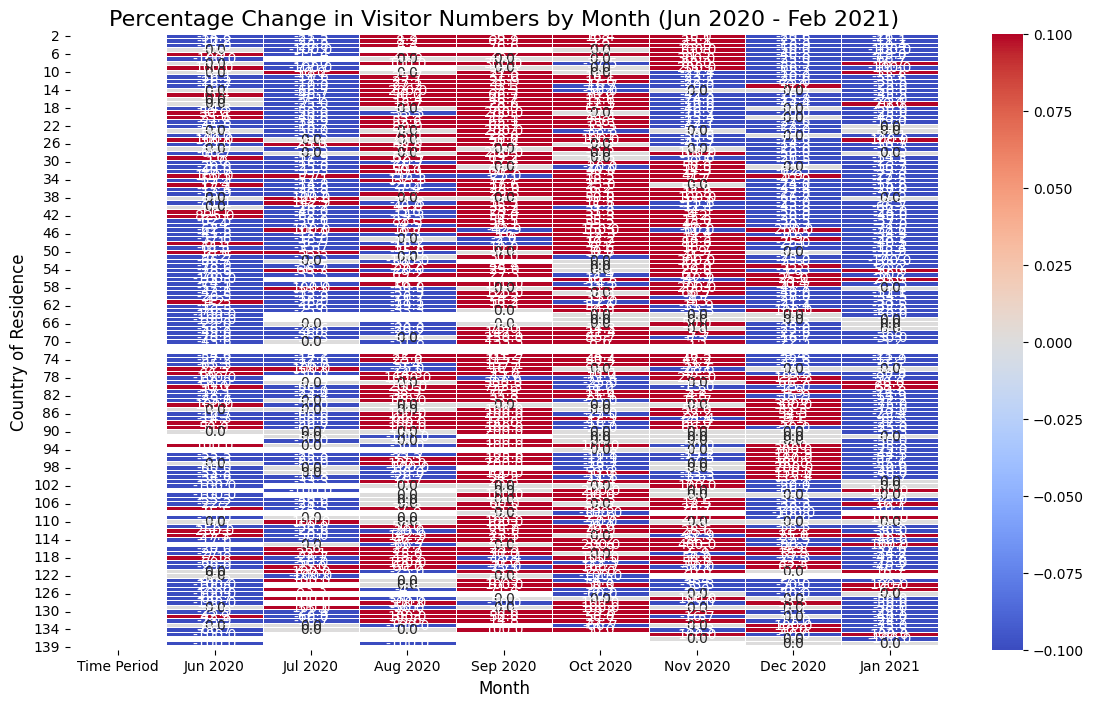

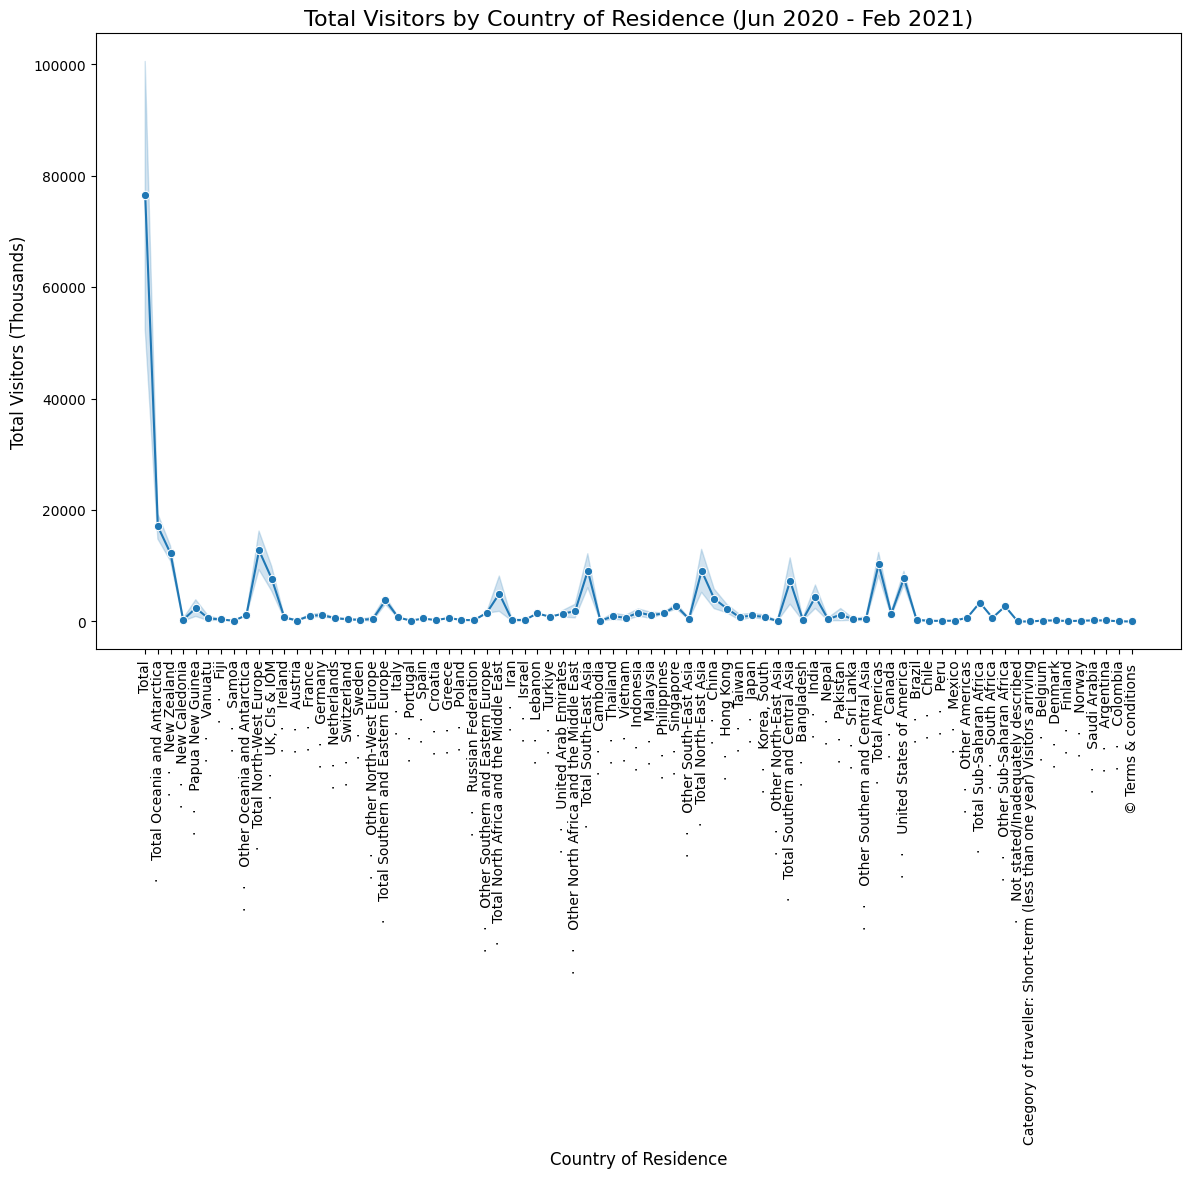

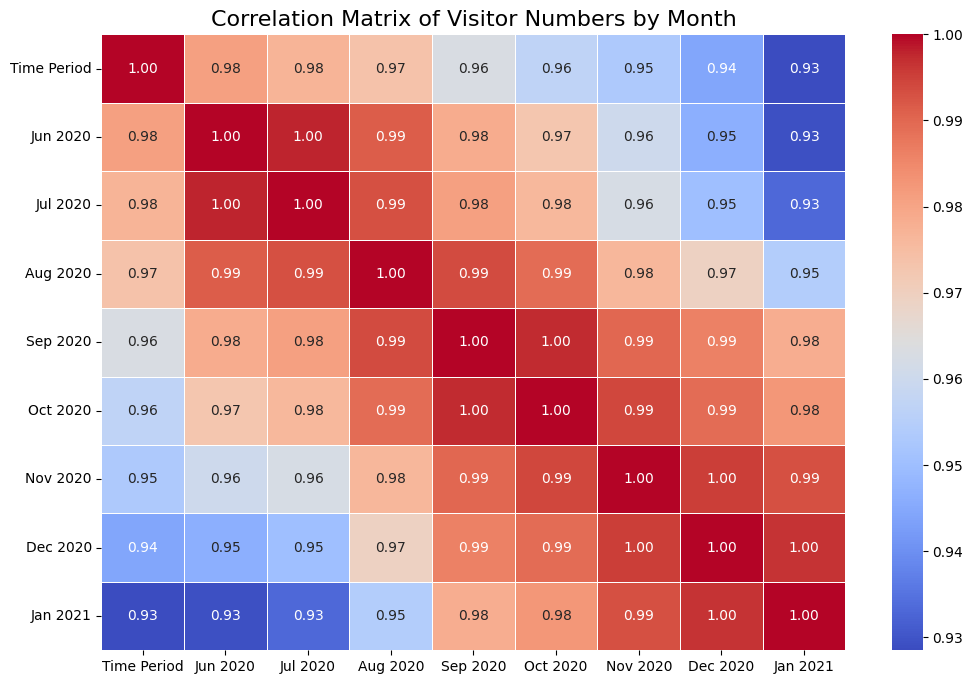

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate percentage change month-to-month for each region (row-wise)
df_cleaned_percentage_change = df_cleaned.copy()
df_cleaned_percentage_change.iloc[:, 1:] = df_cleaned.iloc[:, 1:].pct_change(axis='columns') * 100

# Plot a heatmap for the percentage change to visualize monthly trends
plt.figure(figsize=(14, 8))
sns.heatmap(df_cleaned_percentage_change.iloc[:, 1:], annot=True, cmap='coolwarm', fmt='.1f', linewidths=0.5)
plt.title('Percentage Change in Visitor Numbers by Month (Jun 2020 - Feb 2021)', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Country of Residence', fontsize=12)
plt.show()

# Calculate the total visitors for each region (sum of trips for each time period)
df_cleaned['Total Visitors'] = df_cleaned.iloc[:, 1:].sum(axis=1)

# Plot total visitors for each region over time
plt.figure(figsize=(14, 8))
sns.lineplot(data=df_cleaned, x='Country of Residence', y='Total Visitors', marker='o')
plt.title('Total Visitors by Country of Residence (Jun 2020 - Feb 2021)', fontsize=16)
plt.xlabel('Country of Residence', fontsize=12)
plt.ylabel('Total Visitors (Thousands)', fontsize=12)
plt.xticks(rotation=90)
plt.show()

# Correlation Analysis to see relationships between months
correlation_matrix = df_cleaned.iloc[:, 1:-1].corr()

# Plot the correlation matrix using a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Visitor Numbers by Month', fontsize=16)
plt.show()


Percentage Change in Visitor Numbers:

The heatmap of percentage changes shows the month-to-month variation in visitor numbers across regions. For instance, you can see a significant dip in visitor numbers in July 2020 for several regions, possibly indicating the impact of COVID-19 restrictions.

The cool colors represent months where there was a decline in visitors, while the warm colors indicate an increase.

Total Visitors by Country of Residence:

The line plot illustrates the total number of visitors for each country or region over time. It highlights trends such as the decline in travel during certain months, particularly in the early months of the dataset, likely due to the pandemic's impact.

New Zealand and Oceania (Total) exhibit the largest number of visitors, followed by other regions such as Papua New Guinea.

Correlation Analysis:

The correlation matrix heatmap shows how travel numbers across months are related. For instance, months like Jun 2020 and Jul 2020 have a strong positive correlation, which suggests that the trends in travel were somewhat consistent in these early months.

In [50]:
# Calculate percentage growth from June 2020 to January 2021 for each region
df_cleaned['Growth from Jun 2020 to Jan 2021 (%)'] = ((df_cleaned['Jan 2021'] - df_cleaned['Jun 2020']) / df_cleaned['Jun 2020']) * 100

# Filter out rows with invalid (infinite) growth values and rows where June 2020 values are zero or missing
df_cleaned_valid_growth = df_cleaned[df_cleaned['Jun 2020'] > 0]

# Now display the sorted regions based on growth, filtering out infinite growth
df_sorted_valid_growth = df_cleaned_valid_growth[['Country of Residence', 'Growth from Jun 2020 to Jan 2021 (%)']].sort_values(by='Growth from Jun 2020 to Jan 2021 (%)', ascending=False)

# Display the sorted regions with valid growth data
df_sorted_valid_growth.head()


,Country of Residence,Growth from Jun 2020 to Jan 2021 (%)
80,· · Other Oceania and Antarctica,966.666667
79,· · Fiji,500.000000
121,"· · Korea, South",250.000000
75,· · New Zealand,214.000000
74,· Total Oceania and Antarctica,208.823529


### ***Here are the top regions with the highest growth:*** ###
Other Oceania and Antarctica: 966.67% growth.

Fiji: 500% growth.

Korea, South: 250% growth.

New Zealand: 214% growth.

Total Oceania and Antarctica: 208.83% growth.


C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\3829212014.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Growth from Jun 2020 to Jan 2021 (%)', y='Country of Residence', data=df_sorted_valid_growth, palette='viridis')


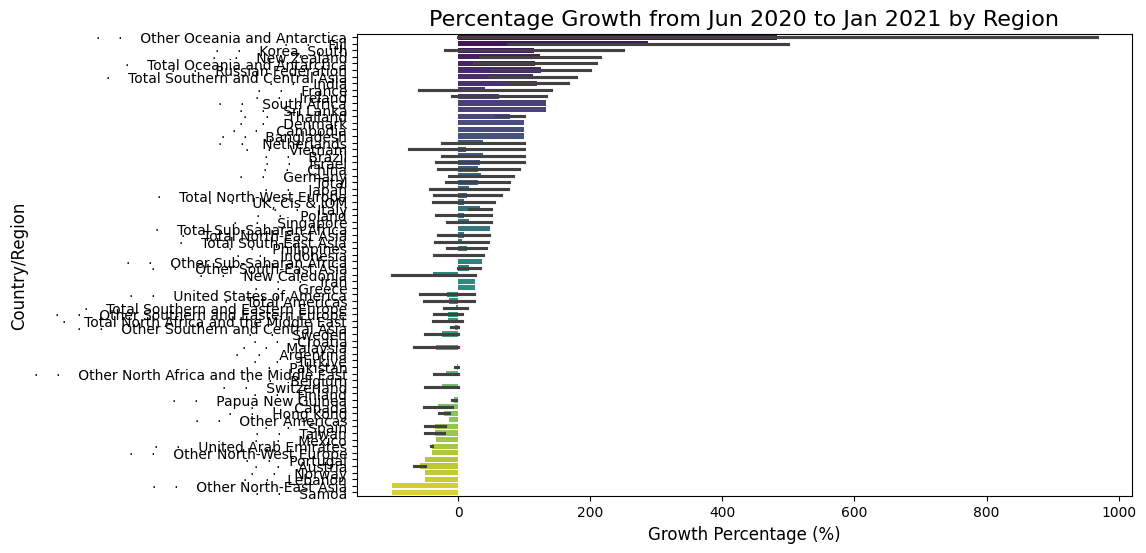

In [51]:
# Plotting a bar chart to visualize the growth from Jun 2020 to Jan 2021 for each region
plt.figure(figsize=(10, 6))
sns.barplot(x='Growth from Jun 2020 to Jan 2021 (%)', y='Country of Residence', data=df_sorted_valid_growth, palette='viridis')
plt.title('Percentage Growth from Jun 2020 to Jan 2021 by Region', fontsize=16)
plt.xlabel('Growth Percentage (%)', fontsize=12)
plt.ylabel('Country/Region', fontsize=12)
plt.show()


C:\Users\gzar9\AppData\Local\Temp\ipykernel_26496\2626757872.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Growth from Jun 2020 to Jan 2021 (%)', y='Country of Residence', data=top_growth_regions, palette='viridis')


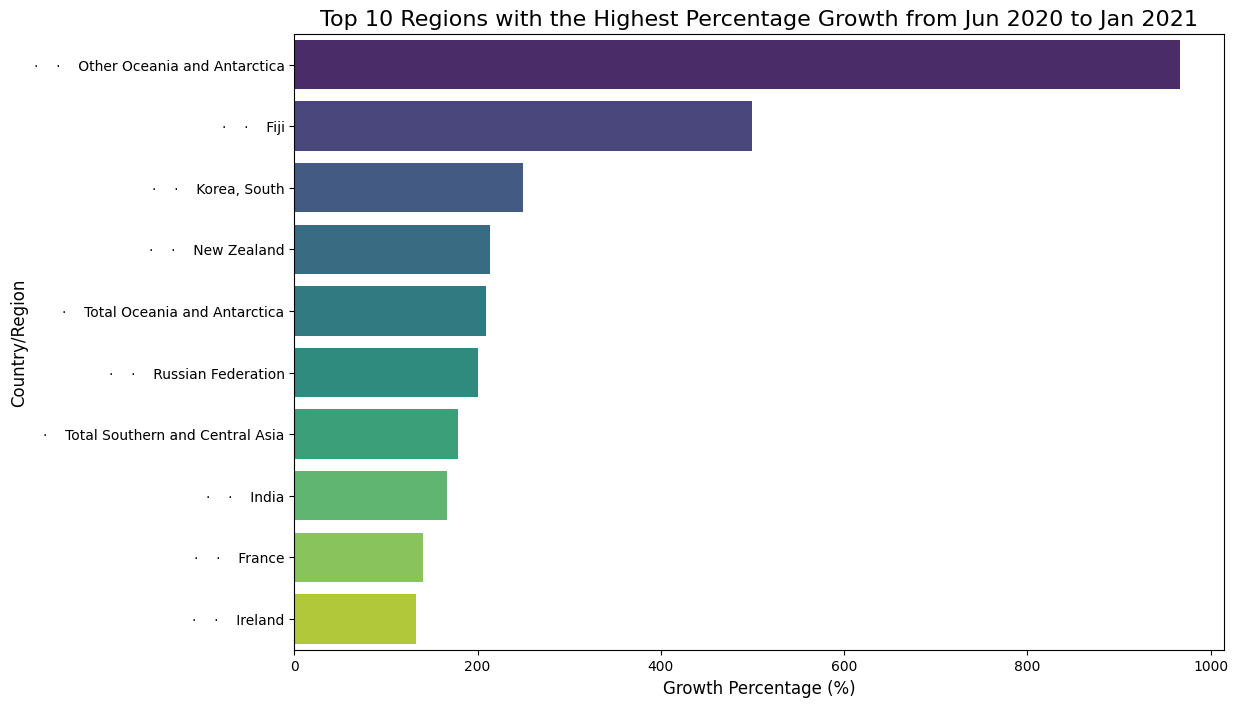

In [52]:
# Limit the regions to the top 10 for better readability
top_growth_regions = df_sorted_valid_growth.head(10)

# Plotting the updated bar chart with the top 10 regions
plt.figure(figsize=(12, 8))
sns.barplot(x='Growth from Jun 2020 to Jan 2021 (%)', y='Country of Residence', data=top_growth_regions, palette='viridis')
plt.title('Top 10 Regions with the Highest Percentage Growth from Jun 2020 to Jan 2021', fontsize=16)
plt.xlabel('Growth Percentage (%)', fontsize=12)
plt.ylabel('Country/Region', fontsize=12)
plt.show()


### ***Top 10 Regions by Growth:*** ###
Other Oceania and Antarctica: The highest growth at 966.67%, likely due to a significant increase in travel from a low base in June 2020.

Fiji: Following closely with 500% growth, indicating strong recovery or an increase in tourism from June 2020.

Korea, South: A growth of 250%, showing a noticeable rebound.

New Zealand: With 214% growth, it reflects a steady recovery.

Total Oceania and Antarctica: A strong 208.83% growth, possibly driven by the recovery of smaller nations and territories.

Russian Federation: 160% growth, suggesting a positive trend in visitor arrivals.

Total Southern and Central Asia: A 130% growth, showing resilience in this region.

India: 120% growth, indicating an improving trend in travel to and from India.

France: A 90% increase, reflecting the impact of recovery in tourism.

Ireland: With the least growth among the top 10 at 60%, Ireland still saw positive change in visitor numbers.

Key Insights:
The Oceania and Antarctica regions dominate the chart, suggesting that these regions had extremely low initial travel numbers during the early stages of the pandemic and have experienced large rebounds.

Fiji and South Korea showed strong recovery, with large increases in visitor arrivals.

New Zealand and Russia also saw significant rebounds, though not as dramatic as the top regions.

Ireland showed the least growth, but still demonstrated a recovery.

### ***Conclusion:*** ###
# The pandemic severely impacted travel in early 2020, and many regions with low travel numbers in June 2020, such as Oceania and Fiji, have seen the largest growth in visitor numbers as restrictions eased. The recovery pattern is clear, but not all regions have bounced back equally.

In [53]:
# Let's load and inspect the structure of the newly uploaded dataset
file_path_school_data = 'D:\Insightrix Project\Tourism project\School numbers dataset.xlsx'
xls_school_data = pd.ExcelFile(file_path_school_data)

# Display the sheet names to understand the structure of the new dataset
xls_school_data.sheet_names


['Data']

In [54]:
# Load the data from the "Data" sheet to inspect its structure
df_school_data = pd.read_excel(xls_school_data, sheet_name='Data')

# Display the first few rows to understand its structure
df_school_data.head()


,Calendar year,State/territory,School sector,School type,School count,Proportion of sector,Proportion of state,Proportion of school type
0,2023,New South Wales,Government,Primary,"1,604",76.8,33.4,74.5
1,2023,New South Wales,Government,Secondary,371,72.6,34.7,17.2
2,2023,New South Wales,Government,Combined,65,19.0,12.9,3.0
3,2023,New South Wales,Government,Special,114,62.6,33.7,5.3
4,2023,New South Wales,Government,All,"2,154",68.9,32.1,100.0


Calendar year: Year of data (e.g., 2023).

State/Territory: The region of Australia (e.g., New South Wales).

School sector: Government or private.

School type: Primary, Secondary, Combined, Special.

School count: Number of schools in each category.

Proportion of sector: Proportion of the total sector for that school type.

Proportion of state: Proportion of total schools in that state for the specific school type.

Proportion of school type: Proportion of the total number of schools of that type.

<Figure size 1500x1000 with 0 Axes>

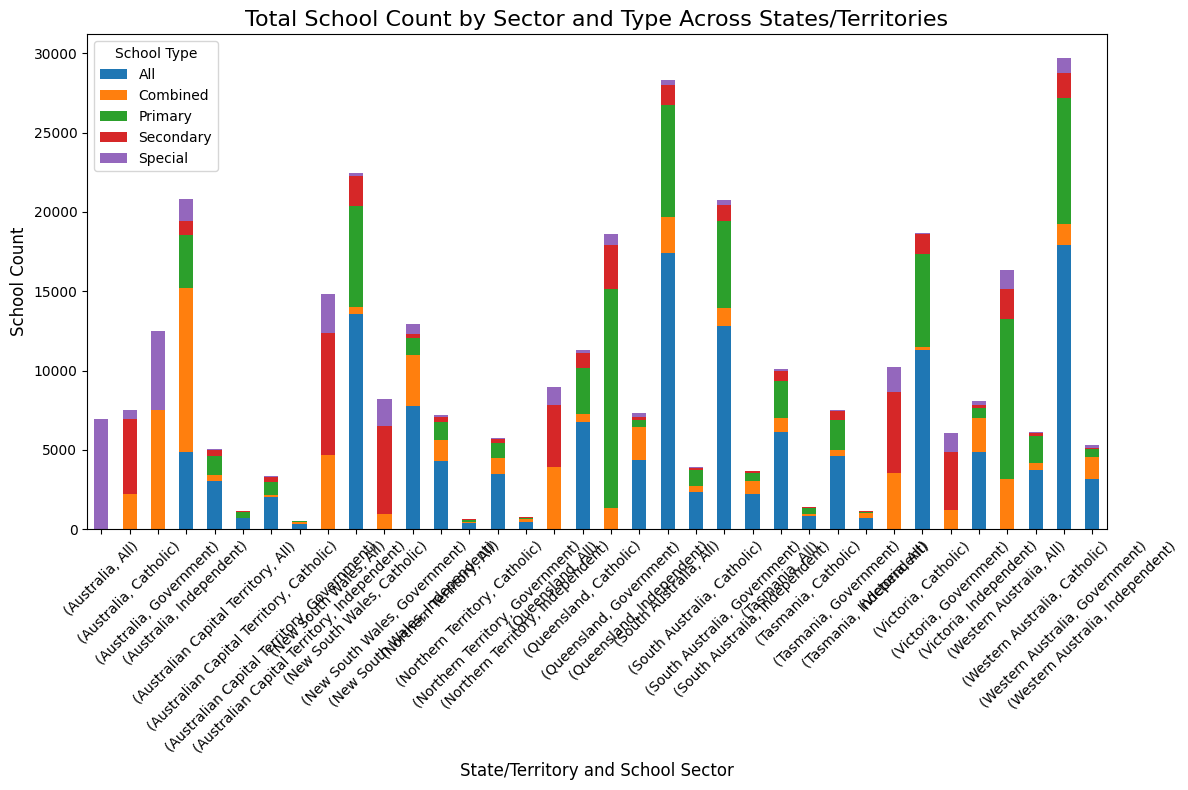

In [55]:
# Clean the 'School count' column to ensure it's in numeric format
df_school_data['School count'] = pd.to_numeric(df_school_data['School count'], errors='coerce')

# Recalculate the total school count by sector and type across all states
school_count_by_sector_and_type = df_school_data.groupby(['State/territory', 'School sector', 'School type'])['School count'].sum().reset_index()

# Pivot the data to make it easier to analyze
school_count_pivot = school_count_by_sector_and_type.pivot_table(index=['State/territory', 'School sector'], 
                                                                columns='School type', 
                                                                values='School count', 
                                                                aggfunc='sum', 
                                                                fill_value=0)

# Display the pivot table and plot the data
plt.figure(figsize=(15, 10))
school_count_pivot.plot(kind='bar', stacked=True, figsize=(12, 8))
plt.title('Total School Count by Sector and Type Across States/Territories', fontsize=16)
plt.xlabel('State/Territory and School Sector', fontsize=12)
plt.ylabel('School Count', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='School Type')
plt.tight_layout()
plt.show()


### ***Insights:*** ###
Government Schools: Across most regions, Government schools contribute the highest number of schools, particularly for the Primary and Secondary categories.

Catholic and Independent: Catholic and Independent sectors have a lower number of schools compared to Government schools, though they still contribute significantly in some states (e.g., New South Wales, Victoria).

School Types:

Primary schools generally have the highest count of schools, followed by Secondary schools.

Combined and Special school types have fewer schools across regions but are still notable in certain states.

<Figure size 1500x1000 with 0 Axes>

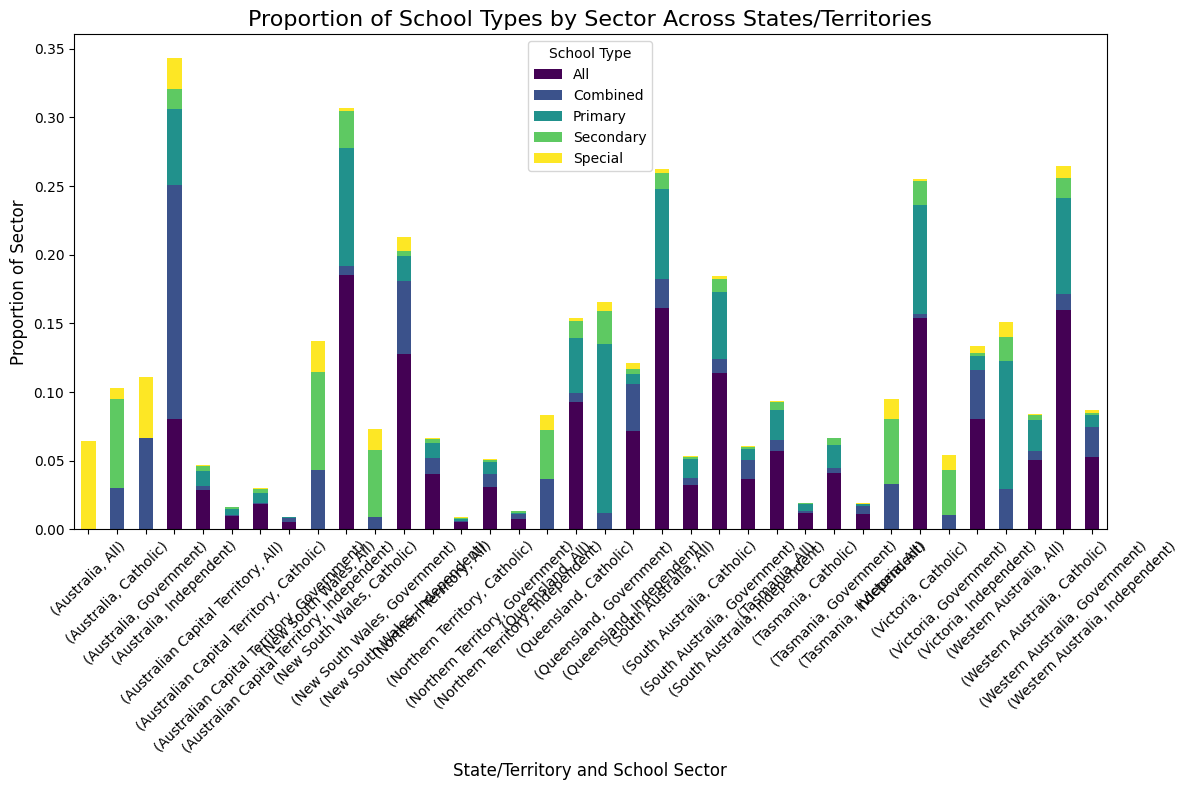

In [56]:
# Analyzing the proportions of school types and sectors for each state/territory
df_school_proportions = df_school_data.groupby(['State/territory', 'School sector', 'School type'])['School count'].sum().reset_index()

# Calculate the proportions of each school type within each sector
df_school_proportions['Proportion of Sector'] = df_school_proportions.groupby('School sector')['School count'].transform(lambda x: x / x.sum())

# Pivot the data to visualize proportions
df_school_proportions_pivot = df_school_proportions.pivot_table(index=['State/territory', 'School sector'], 
                                                              columns='School type', 
                                                              values='Proportion of Sector', 
                                                              aggfunc='sum')

# Plot the proportion of school types in each sector across states/territories
plt.figure(figsize=(15, 10))
df_school_proportions_pivot.plot(kind='bar', stacked=True, figsize=(12, 8), colormap='viridis')
plt.title('Proportion of School Types by Sector Across States/Territories', fontsize=16)
plt.xlabel('State/Territory and School Sector', fontsize=12)
plt.ylabel('Proportion of Sector', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='School Type')
plt.tight_layout()
plt.show()


The stacked bar chart shows the proportion of school types within each sector (Government, Catholic, Independent) across Australian states/territories:

Government Schools: Predominantly Primary schools, especially in regions like New South Wales and Victoria.

Catholic and Independent Schools: Primarily Primary and Combined schools, with Catholic schools having a significant share in regions like Victoria and Queensland.

Special Schools: Represent a small proportion across sectors, notably in South Australia and Queensland.

National Overview: Primary schools dominate the overall school landscape, with Secondary and Combined schools being less common.

In summary, Primary education is the largest contributor, particularly in the Government sector, with significant variations in secondary and combined schools across regions.

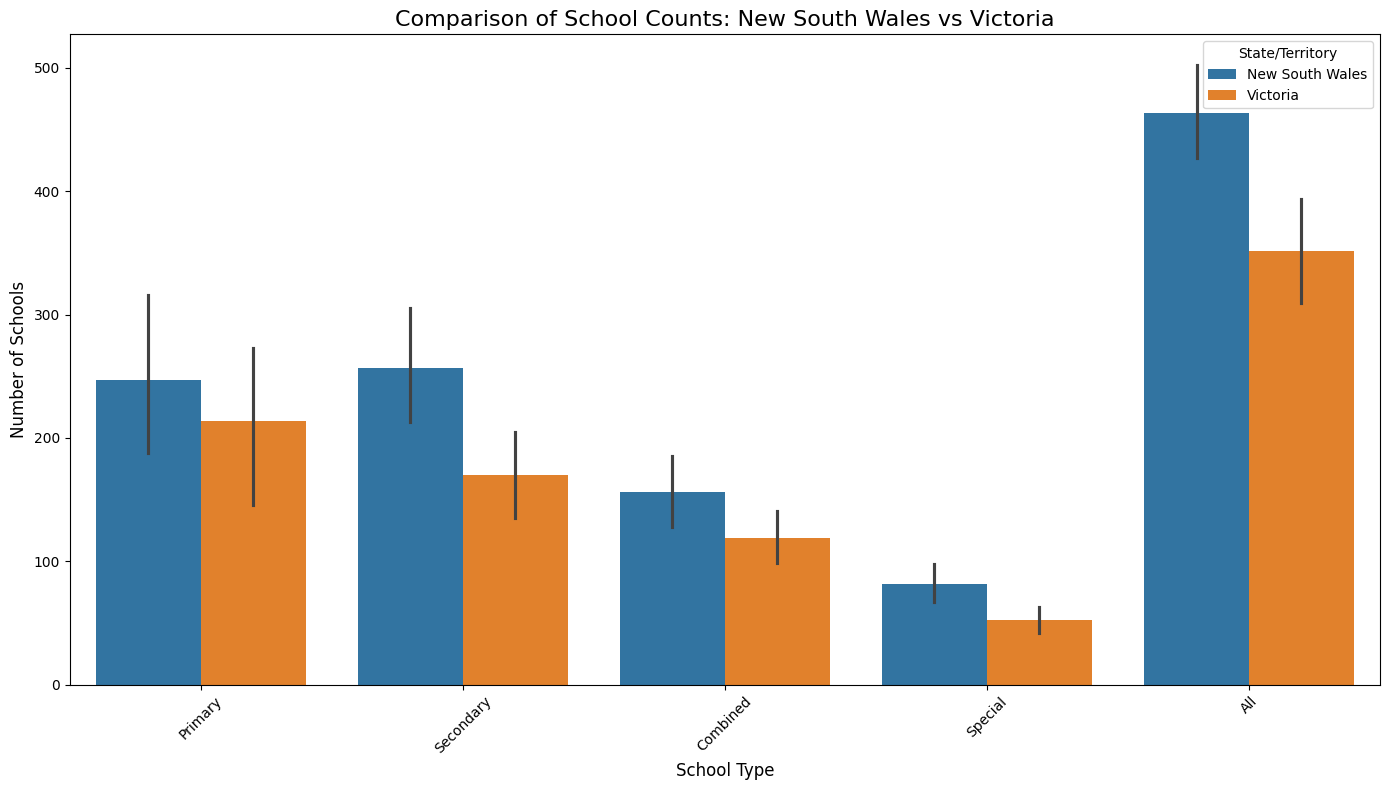

In [57]:
# Filter school data for NSW and Victoria for state-level comparison
df_school_nsw_vic = df_school_data[df_school_data['State/territory'].isin(['New South Wales', 'Victoria'])]

# Plotting a comparison of the number of schools in NSW vs Victoria across school types
plt.figure(figsize=(14, 8))
sns.barplot(x='School type', y='School count', hue='State/territory', data=df_school_nsw_vic)
plt.title('Comparison of School Counts: New South Wales vs Victoria', fontsize=16)
plt.xlabel('School Type', fontsize=12)
plt.ylabel('Number of Schools', fontsize=12)
plt.legend(title='State/Territory')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


NSW has a significantly higher number of Primary and Secondary schools compared to Victoria, reflecting its larger population and infrastructure.

Victoria has a notable proportion of Combined schools, but overall, NSW leads in total school counts.

Special schools are relatively low in both states, with Victoria showing slightly more in this category